# Drive failure baseline: end to end

This notebook follows the project in order: **data → failure profile → the
parameters it led to → splits and leakage checks → models → results**. It
calls the same package code as the command line (`dfb …`), so its numbers
match the reports. Each parameter links to its entry in
[`docs/decisions.md`](../docs/decisions.md).

It reads the prepared data (`dfb prepare`, `dfb features`) and finished runs
(`dfb bench`); it does not retrain anything.

In [1]:
import json, pathlib
import pandas as pd
import matplotlib.pyplot as plt
from dfb import config

ROOT = config.ROOT
pd.set_option("display.max_columns", 30)

# Chart style: one hue per series in fixed order, recessive axes, text in ink colours.
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10})

## 1. Data

Twelve quarters of Backblaze Drive Stats, 2023 Q4 to 2026 Q3
([D-1, D-2](../docs/decisions.md)), downloaded from Backblaze and converted
to one declared schema, `drive_stats_v1` ([D-6](../docs/decisions.md)).
Every source file's checksum is frozen in `benchmark/v1/benchmark.json`.

In [2]:
manifest = json.loads(config.MANIFEST.read_text())
pd.DataFrame({q: {"rows": v["rows"], "days": v["days"], "zip_GB": round(v["zip_bytes"] / 1e9, 2),
                  "capacity not reported (rows)": v.get("unknown_capacity_rows"),
                  "schema": v.get("schema")} for q, v in manifest.items()}).T

,rows,days,zip_GB,capacity not reported (rows),schema
Q1_2024,25189213,91,1.01,9520,drive_stats_v1
Q1_2025,27799986,90,1.02,0,drive_stats_v1
Q1_2026,30597484,90,1.31,0,drive_stats_v1
Q2_2024,26022269,91,1.02,4411,drive_stats_v1
Q2_2025,28808042,91,1.07,0,drive_stats_v1
Q2_2026,31968003,91,2.09,0,drive_stats_v1
Q3_2024,26822987,92,1.05,10566,drive_stats_v1
Q3_2025,29844451,92,1.11,0,drive_stats_v1
Q3_2026,33318960,92,1.83,0,drive_stats_v1
Q4_2023,24790999,92,1.01,8390,drive_stats_v1


In [3]:
from dfb.benchmark import verify
problems = verify()
print("local data matches benchmark v1" if not problems else problems)

local data matches benchmark v1


## 2. Failure profile: what the data says before any model

Full report: [`reports/failure_profile.md`](../reports/failure_profile.md).
The failure rate is Backblaze's annualized failure rate, AFR = failures ÷
(drive-days ÷ 365) ([F-5](../docs/decisions.md)).

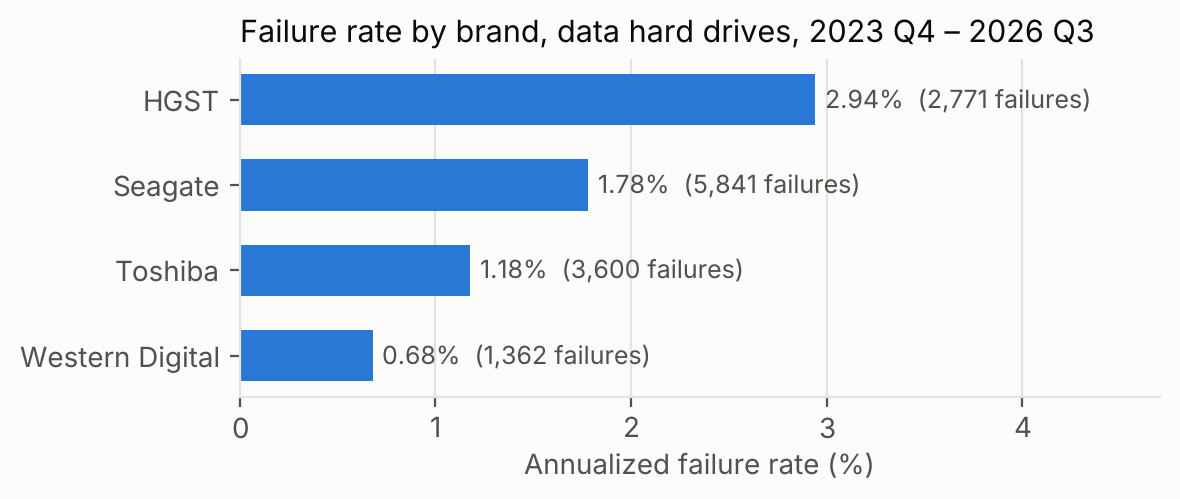

,brand,kind,models,drives,drive_days,failures,afr_pct,share_of_failures_pct
3,Western Digital,data HDD,8,97404,73328432,1362,0.68,9.9
1,Toshiba,data HDD,12,140259,111212035,3600,1.18,26.2
0,Seagate,data HDD,32,137521,120000979,5841,1.78,42.5
2,HGST,data HDD,15,41985,34436786,2771,2.94,20.2


In [4]:
brands = pd.read_csv(ROOT / "reports/profile_brands.csv")
data_hdd = brands[brands["kind"] == "data HDD"].sort_values("afr_pct")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(data_hdd["brand"], data_hdd["afr_pct"], color=SERIES[0], height=0.6)
for y, (v, f) in enumerate(zip(data_hdd["afr_pct"], data_hdd["failures"])):
    ax.text(v + 0.05, y, f"{v:.2f}%  ({f:,} failures)", va="center", color=INK2, fontsize=9)
ax.set_xlabel("Annualized failure rate (%)")
ax.set_title("Failure rate by brand, data hard drives, 2023 Q4 – 2026 Q3", loc="left", fontsize=11)
ax.grid(axis="y", visible=False); ax.set_xlim(0, data_hdd["afr_pct"].max() * 1.6)
plt.tight_layout(); plt.show()
data_hdd

Brand matters less than the specific drive model: among Seagate models with at
least 30 failures, rates range from about 0.6% to 7.8% a year. Failures are concentrated: the top 10 drive
models hold about 70% of failures.

In [5]:
models = pd.read_csv(ROOT / "reports/profile_models.csv", index_col=0)
models[models["kind"] == "data HDD"].head(10)[
    ["brand", "capacity_tb", "drives", "failures", "afr_pct", "failures_test", "quarters_present"]]

,brand,capacity_tb,drives,failures,afr_pct,failures_test,quarters_present
model,,,,,,,
ST12000NM0008,Seagate,12.0,19782,1538,2.71,296,12
HGST HUH721212ALN604,HGST,12.0,10924,1471,4.88,282,12
TOSHIBA MG07ACA14TA,Toshiba,14.0,38218,1282,1.14,252,12
TOSHIBA MG08ACA16TA,Toshiba,16.0,40992,1209,1.05,162,12
HGST HUH721212ALE604,HGST,12.0,14158,1103,2.78,178,12
ST8000NM0055,Seagate,8.0,14007,990,2.46,220,12
ST16000NM001G,Seagate,16.0,36366,598,0.60,97,12
TOSHIBA MG08ACA16TEY,Toshiba,16.0,5306,522,3.45,68,12
ST8000DM002,Seagate,8.0,9316,473,1.87,84,12


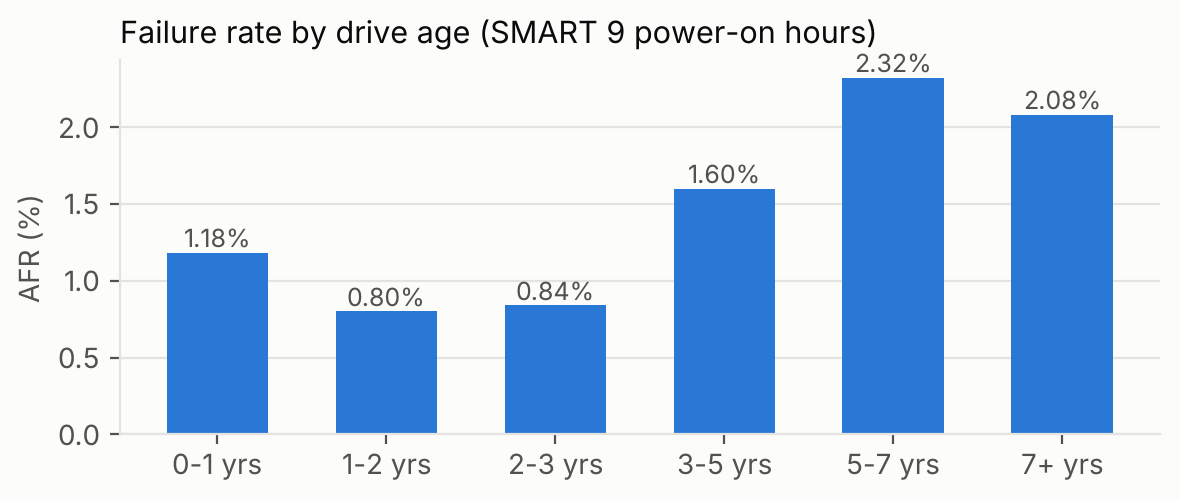

In [6]:
age = pd.read_csv(ROOT / "reports/profile_age.csv")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(age["age_band"], age["afr_pct"], color=SERIES[0], width=0.6)
for x, v in enumerate(age["afr_pct"]):
    ax.text(x, v + 0.04, f"{v:.2f}%", ha="center", color=INK2, fontsize=9)
ax.set_ylabel("AFR (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Failure rate by drive age (SMART 9 power-on hours)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 3. Decisions the profile led to

| Question | Evidence | Decision |
|---|---|---|
| Shorten the 3-year window? | Training windows of 0.5–2 years all cover ~98% of test drives' models, but 2 years has ~4× the failures | Keep 12 quarters ([D-2](../docs/decisions.md)) |
| Drop the two quarters missing SMART 211/212? | Those columns have values in 0.003% of rows, all from boot SSDs | Keep them ([D-7](../docs/decisions.md)) |
| Which drives? | Boot drives have ~160 failures in 3 years, none in test | Data hard drives only ([R-1](../docs/decisions.md)) |
| Which models to train on? | 99.99% of drives already needs 58 of 67 models | All 67 ([R-2](../docs/decisions.md)) |
| Which models get their own result? | A rate from 1 failure can only be 0% or 100% | ≥ 30 test failures ([R-3](../docs/decisions.md)) |

In [7]:
pd.read_csv(ROOT / "reports/profile_window.csv", index_col=0)

,training drive-days,training failures,models with >= 10 training failures,test drives whose model is seen in training pct,test drives whose model has >= 10 training failures pct,test failures whose model has >= 10 training failures pct
training window,,,,,,
Q2_2025 to Q3_2025 (0.5 yr),58652493,2307,23,98.0,91.3,96.5
Q4_2024 to Q3_2025 (1 yr),113797771,4406,25,98.0,91.4,96.6
Q2_2024 to Q3_2025 (1.5 yr),166643027,7058,30,98.0,91.7,96.6
Q4_2023 to Q3_2025 (2 yr),216623239,9093,34,98.0,91.9,96.6


## 4. Splits and leakage checks

Split by time ([S-1 to S-4](../docs/decisions.md)). A day is used only if its
label is decided inside its own period ([L-2](../docs/decisions.md)). The
check below runs the leakage rules on the full feature tables.

In [8]:
from dfb.splits import summarize
print(summarize())

# Splits and leakage check

Generated by `dfb splits` from `data/features/`. Data hard drives only (R-1).

## Leakage rules checked on the real data

- train: every date inside 2023-10-01 to 2025-09-30 (found 2023-10-01 to 2025-09-30); one period tag
- valid: every date inside 2025-10-01 to 2026-03-31 (found 2025-10-01 to 2026-03-31); one period tag
- test: every date inside 2026-04-01 to 2026-09-30 (found 2026-04-01 to 2026-09-30); one period tag
- no row falls after its drive's failure date
- labels: a row is used only if its N-day label is decided inside its own period (the window ends inside it, or the drive fails inside both the window and the period); counts below are after that rule (L-2)

## Counts per split

| split | N (days) | rows used | drives | failed drives in split | positive rows | weighted share positive |
|---|---|---|---|---|---|---|
| train | 7 | 4,483,949 | 355,607 | 8,935 | 58,797 | 0.0278% |
| train | 14 | 4,436,656 | 354,696 | 8,935 | 118,096 | 0.0564% |
| trai

## 5. Results

Thresholds are set on **validation** and applied unchanged to test
([E-2](../docs/decisions.md)); failures are counted per drive
([B-1, E-1](../docs/decisions.md)). Full method: [`EVALUATION.md`](../EVALUATION.md).

In [9]:
from dfb.report import load, LEVEL_NAMES, METHOD_NAMES
runs = load()
n7 = runs[runs["n"] == 7]
summary = (n7.groupby(["level", "method", "features"])
             .agg(seeds=("seed", "size"),
                  caught_at_1pct=("det_1pct", "mean"), sd=("det_1pct", "std"),
                  actual_false_alarm=("far_1pct", "mean"),
                  caught_at_0_1pct=("det_0.1pct", "mean"),
                  warning_days=("warn_1pct", "mean"), pr_auc=("pr_auc", "mean"))
             .round(4))
summary

seeds  caught_at_1pct      sd  actual_false_alarm  \
level method features                                                      
L0    M0     core          1          0.0000     NaN              0.0000   
L1    M0     core          1          0.2003     NaN              0.0049   
L2    M0     core          3          0.5498  0.0000              0.0113   
      M1     core          3          0.5357  0.0012              0.0118   
      M2     core          3          0.5361  0.0028              0.0117   
      M3     core          3          0.4267  0.1578              0.0135   
L3    M0     core          3          0.4166  0.0059              0.0103   
L4    M0     core          3          0.5213  0.0052              0.0110   
             full          3          0.5214  0.0065              0.0106   
      M1     core          3          0.4975  0.0071              0.0115   
      M2     core          3          0.4329  0.0144              0.0116   
      M3     core          3          0.5079  0.0083              0.0113   

                       caught_at_0_1pct  warning_days  pr_auc  
level method features                                          
L0    M0     core                0.0000           NaN  0.0072  
L1    M0     core                0.1179        6.0000  0.1714  
L2    M0     core                0.1813        6.0000  0.3029  
      M1     core                0.1825        6.0000  0.2868  
      M2     core                0.1808        6.0000  0.2878  
      M3     core                0.1376        5.6667  0.2014  
L3    M0     core                0.1243        6.0000  0.2293  
L4    M0     core                0.1501        6.0000  0.2775  
             full                0.1578        6.0000  0.2779  
      M1     core                0.1430        5.0000  0.2574  
      M2     core                0.1518        5.0000  0.2280  
      M3     core                0.1524        5.6667  0.2717

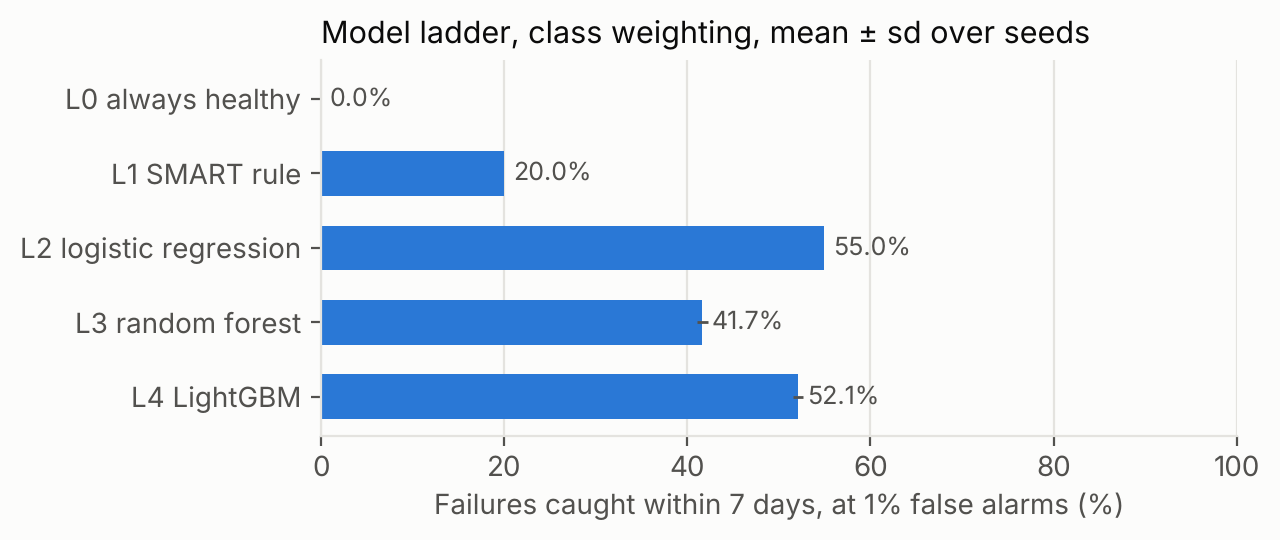

In [10]:
core = summary.reset_index()
core = core[(core["features"] == "core") & (core["method"] == "M0")]
labels = [LEVEL_NAMES[l] for l in core["level"]]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(labels, core["caught_at_1pct"] * 100, color=SERIES[0], height=0.6,
        xerr=core["sd"].fillna(0) * 100, error_kw={"ecolor": INK2, "elinewidth": 1})
for y, v in enumerate(core["caught_at_1pct"] * 100):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, 100)
ax.set_xlabel("Failures caught within 7 days, at 1% false alarms (%)")
ax.set_title("Model ladder, class weighting, mean ± sd over seeds", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

### Resampling vs synthetic failures

M2 (SMOTE) and M3 (CTGAN) add exactly the same number of failure rows on
identical splits ([E-3](../docs/decisions.md)).

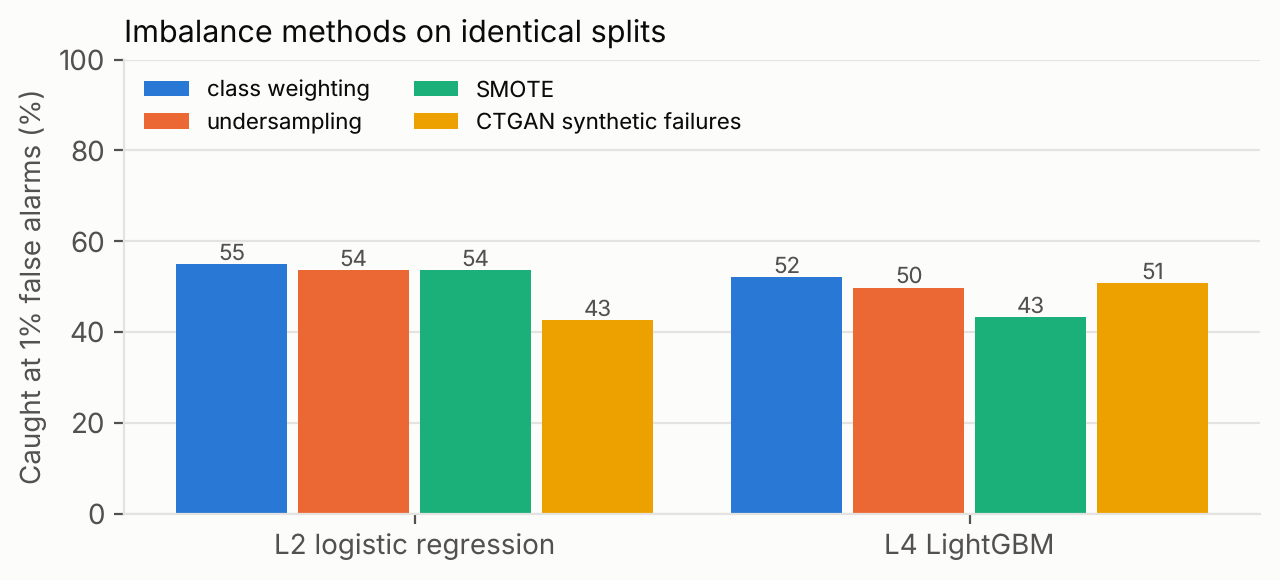

In [11]:
import numpy as np
cmp = summary.reset_index()
cmp = cmp[(cmp["features"] == "core") & cmp["level"].isin(["L2", "L4"])]
methods = ["M0", "M1", "M2", "M3"]
fig, ax = plt.subplots(figsize=(6.5, 3))
w = 0.2
for i, me in enumerate(methods):
    vals = [cmp[(cmp["level"] == lv) & (cmp["method"] == me)]["caught_at_1pct"].mean() * 100
            for lv in ["L2", "L4"]]
    xs = np.arange(2) + (i - 1.5) * (w + 0.02)
    ax.bar(xs, vals, width=w, color=SERIES[i], label=METHOD_NAMES[me])
    for x, v in zip(xs, vals):
        if not np.isnan(v):
            ax.text(x, v + 1, f"{v:.0f}", ha="center", color=INK2, fontsize=8)
ax.set_xticks(range(2), [LEVEL_NAMES["L2"], LEVEL_NAMES["L4"]])
ax.set_ylabel("Caught at 1% false alarms (%)"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
ax.set_ylim(0, 100)
ax.set_title("Imbalance methods on identical splits", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

### Why default SMOTE lowered detection (decisions M-4, M-5)

As declared, SMOTE and CTGAN trained on their added rows without the
training sampling weights that class weighting uses, and two-thirds of
SMOTE's new rows blend a failing drive with one of its own other days.
A settings study, scored on the **validation** period only, tests each
cause; the chosen setting, and CTGAN with the same weighting, were then
run once on test.

In [12]:
from IPython.display import Markdown
from dfb.report import smote_study_section
Markdown("\n".join(smote_study_section()[2:]))

Decision M-4. LightGBM, 7 days, core features, seed 0. Each variant is scored on the **validation** period only (threshold set on validation); the best SMOTE variant was then run once on test. "Same-drive pairs" is the share of new rows made by blending a failing drive with one of its own other days. The training table already holds about 75 healthy rows per failure row, so at 100:1 nothing is added: that row is LightGBM with neither sampling weights nor added rows.

| Variant | Rows added | Same-drive pairs | Blended brand or flag | Caught at 1% (validation) | Caught at 0.1% (validation) | PR-AUC (validation) |
|---|---|---|---|---|---|---|
| M0 class weighting (reference) | – | – | – | 45.8% | 15.4% | 0.226 |
| M2 as run (imblearn, k=5, 10:1) | 383,719 | – | – | 37.4% | 12.8% | 0.184 |
| SMOTE k=5, 10:1 (same as M2) | 383,719 | 66.1% | 0.4% | 36.8% | 15.0% | 0.178 |
| k=3 | 383,719 | 76.6% | 0.2% | 38.1% | 13.0% | 0.168 |
| k=10 | 383,719 | 38.4% | 0.7% | 39.9% | 14.1% | 0.189 |
| k=25 | 383,719 | 16.5% | 1.5% | 43.0% | 15.2% | 0.208 |
| ratio 25:1 | 118,210 | 66.0% | 0.4% | 39.6% | 16.5% | 0.207 |
| ratio 50:1 | 29,707 | 65.8% | 0.3% | 41.6% | 14.3% | 0.199 |
| ratio 100:1 | 0 | – | – | 42.7% | 13.9% | 0.204 |
| cross-drive neighbours | 383,719 | 0.0% | 1.1% | 40.7% | 15.6% | 0.217 |
| categorical columns kept | 383,719 | 66.1% | 0.0% | 39.0% | 12.6% | 0.178 |
| sampling weights kept | 383,719 | 66.1% | 0.4% | 44.5% | 15.4% | 0.222 |
| cross-drive + categorical + weights | 383,719 | 0.0% | 0.0% | 47.4% | 17.6% | 0.239 |

**Test period**, LightGBM, 7 days, threshold set on validation, 3 seeds. Corrected = sampling weights kept with class balancing (both), and for SMOTE neighbours from other drives with brand and flag columns copied. Both add the same number of rows.

| Method | Caught at 1% false alarms | (actual false-alarm %) | Caught at 0.1% false alarms | Median days of warning | PR-AUC |
|---|---|---|---|---|---|
| Class weighting (M0) | 52.1 ± 0.5% | 1.10 ± 0.02 | 15.0 ± 1.1% | 6.0 ± 0.0 | 0.277 ± 0.005 |
| SMOTE, first setup (M2) | 43.3 ± 1.4% | 1.16 ± 0.08 | 15.2 ± 0.9% | 5.0 ± 0.0 | 0.228 ± 0.011 |
| CTGAN, first setup (M3) | 50.8 ± 0.8% | 1.13 ± 0.05 | 15.2 ± 0.6% | 5.7 ± 0.6 | 0.272 ± 0.005 |
| SMOTE, other-drive neighbours + weights (M-4) | 54.4 ± 0.5% | 1.05 ± 0.03 | 14.8 ± 0.7% | 6.0 ± 0.0 | 0.282 ± 0.006 |
| CTGAN + weights (M-5) | 53.7 ± 0.5% | 1.11 ± 0.03 | 16.7 ± 0.8% | 6.0 ± 0.0 | 0.282 ± 0.005 |


### Improvement study (decision M-6)

Sixteen settings were tried on the **validation** period only: LightGBM
settings, logistic regression regularisation, corrected SMOTE on the best
models, a blend of the two model types, and per-brand thresholds. The
best LightGBM, the best logistic regression and the best overall then ran
once on test with 3 seeds. Every attempt is logged in
[`experiments.csv`](../results/improvement_study/experiments.csv).

In [13]:
from dfb.report import improvement_section
Markdown("\n".join(improvement_section()[2:]))

Every attempt, in the order it was run, copied from `results/improvement_study/experiments.csv` (one row per run, never overwritten). 7 days, core features. Stages A–D are scored on the **validation** period only (seed 0, threshold set on validation). The validation threshold sample (a fixed 25% of drives) holds 454 failing drives, so one drive is 0.22 points and differences under about 3 points are within chance.

| ID | Stage | What changed | Thresholds | Caught at 1% (validation) | Caught at 0.1% (validation) | PR-AUC (validation) | Fit seconds |
|---|---|---|---|---|---|---|---|
| A1 | A | LightGBM, benchmark settings (reference) | global | 45.8% | 15.4% | 0.226 | 33 |
| A2 | A | LightGBM, 31 leaves | global | 45.2% | 14.3% | 0.217 | 27 |
| A3 | A | LightGBM, 127 leaves | global | 47.8% | 17.4% | 0.228 | 34 |
| A4 | A | LightGBM, at least 500 rows per leaf | global | 47.4% | 15.2% | 0.220 | 32 |
| A5 | A | LightGBM, at least 20 rows per leaf | global | 45.8% | 15.4% | 0.221 | 29 |
| A6 | A | LightGBM, learning rate 0.05, up to 600 trees | global | 46.9% | 14.8% | 0.224 | 56 |
| A7 | A | LightGBM, L2 regularisation 10 | global | 48.7% | 13.9% | 0.219 | 30 |
| A8 | A | LightGBM, 50% of features per tree | global | 47.6% | 15.0% | 0.226 | 38 |
| B1 | B | Logistic regression, C = 1 (reference) | global | 49.6% | 16.1% | 0.235 | 88 |
| B2 | B | Logistic regression, C = 0.1 | global | 49.6% | 16.1% | 0.234 | 91 |
| B3 | B | Logistic regression, C = 10 | global | 49.3% | 16.1% | 0.235 | 85 |
| A9 | A | LightGBM, improving changes combined: {"learning_rate": 0.05, "min_data_in_leaf": 500, "feature_fraction": 0.5, "num_leaves": 127, "lambda_l2": 10.0} | global | 48.2% | 16.5% | 0.233 | 84 |
| C1 | C | A7 with corrected SMOTE rows | global | 46.5% | 15.0% | 0.231 | 44 |
| C2 | C | B1 with corrected SMOTE rows | global | 48.9% | 15.2% | 0.231 | 92 |
| D1 | D | Blend: mean calibrated probability of A7 and B1 | global | 51.8% | 15.9% | 0.245 | 0 |
| D2 | D | D1 with per-brand thresholds | per brand | 47.4% | 13.9% | 0.245 | 0 |

**Test period**, chosen before test was opened: the best LightGBM, the best logistic regression and the best overall on validation. 3 seeds, thresholds set on validation and applied unchanged. Benchmark rows first, for comparison.

| Configuration | Caught at 1% false alarms | (actual false-alarm %) | Caught at 0.1% false alarms | Median days of warning | PR-AUC |
|---|---|---|---|---|---|
| LightGBM, benchmark settings (L4-M0) | 52.1 ± 0.5% | 1.10 ± 0.02 | 15.0 ± 1.1% | 6.0 ± 0.0 | 0.277 ± 0.005 |
| Logistic regression, benchmark settings (L2-M0) | 55.0 ± 0.0% | 1.13 ± 0.00 | 18.1 ± 0.0% | 6.0 ± 0.0 | 0.303 ± 0.000 |
| A7: LightGBM, L2 regularisation 10 | 52.9 ± 0.6% | 1.09 ± 0.02 | 15.5 ± 0.2% | 6.0 ± 0.0 | 0.282 ± 0.006 |
| B1: Logistic regression, C = 1 (reference) | 55.0 ± 0.0% | 1.13 ± 0.00 | 18.1 ± 0.0% | 6.0 ± 0.0 | 0.303 ± 0.000 |
| D1: Blend: mean calibrated probability of A7 and B1 | 57.7 ± 0.2% | 1.09 ± 0.01 | 18.0 ± 0.8% | 6.0 ± 0.0 | 0.309 ± 0.004 |


### By slice (headline model: LightGBM, class weighting, seed 0)

Detection rates only for slices with at least 30 test failures
([R-3](../docs/decisions.md)); drive models unseen in training are a separate
slice ([R-4](../docs/decisions.md)).

In [14]:
head = ROOT / "results/benchmark_v1/N7/L4-M0-core-seed0"
for col in ["brand", "capacity_tb", "age_band", "new_model"]:
    p = head / f"slice_{col}.csv"
    if p.exists():
        display(pd.read_csv(p))

,brand,failures,healthy_drives,detection_rate,false_alarm_rate,note
0,Seagate,1143,112496,0.559055,0.010596,NaN
1,Toshiba,692,135460,0.450867,0.006873,NaN
2,HGST,472,25232,0.578390,0.033014,NaN
3,Western Digital,374,95924,0.454545,0.011363,NaN


,capacity_tb,failures,healthy_drives,detection_rate,false_alarm_rate,note
0,12.0,870,58387,0.649425,0.022145,NaN
1,16.0,584,117962,0.390411,0.011461,NaN
2,14.0,410,58703,0.592683,0.010306,NaN
3,8.0,307,20216,0.527687,0.014691,NaN
4,24.0,226,25181,0.119469,0.004448,NaN
5,20.0,131,30008,0.526718,0.005199,NaN
6,22.0,96,50399,0.729167,0.003115,NaN
7,26.0,30,7202,0.566667,0.007359,NaN
8,10.0,27,986,NaN,0.021298,too few to measure
9,18.0,0,68,NaN,0.000000,too few to measure


,age_band,failures,healthy_drives,detection_rate,false_alarm_rate,note
0,5-7,997,109030,0.662989,0.014978,NaN
1,3-5,491,79100,0.401222,0.012541,NaN
2,0-1,450,65245,0.444444,0.007188,NaN
3,7+,316,12740,0.582278,0.030377,NaN
4,1-2,283,50413,0.314488,0.004463,NaN
5,2-3,139,52582,0.453237,0.006466,NaN
6,NaN,5,2,NaN,0.000000,too few to measure


,new_model,failures,healthy_drives,detection_rate,false_alarm_rate,note
0,False,2649,361723,0.519819,0.011039,NaN
1,True,32,7389,0.531250,0.007173,NaN


## 6. Limits

One operator's fleet, hard drives and SMART data only; some SMART signals
exist for one brand only. The benchmark is a documented, reproducible
evaluation protocol, not a community standard.